# Module 8 Lab 1: AI-Assisted EDA, Verified

## Step 1: Open Colab and load the penguins

Create a Colab notebook named module8_lab.ipynb, upload penguins.csv (Tutorial 1), and load it with pandas.

In [24]:
import pandas as pd

df= pd.read_csv("/content/drive/MyDrive/penguins.csv")
df.info(), df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB


(None,
   species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
 0  Adelie  Torgersen            39.1           18.7              181.0   
 1  Adelie  Torgersen            39.5           17.4              186.0   
 2  Adelie  Torgersen            40.3           18.0              195.0   
 3  Adelie  Torgersen             NaN            NaN                NaN   
 4  Adelie  Torgersen            36.7           19.3              193.0   
 
    body_mass_g     sex  year  
 0       3750.0    male  2007  
 1       3800.0  female  2007  
 2       3250.0  female  2007  
 3          NaN     NaN  2007  
 4       3450.0  female  2007  )

## Step 2: Establish ground truth by hand, no AI

Record in code and markdown: the shape, the missing-value counts per column, and the number of penguins of each species.

In [25]:
df.shape

(344, 8)

In [26]:
df.isnull().sum()

,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11
year,0


In [27]:
df['species'].value_counts()

,count
species,
Adelie,152
Gentoo,124
Chinstrap,68


Penguins.csv is a file containing 344 rows and 8 columns. 5 columns contain missing rows, bill_length_mm, bill_depth_mm, flipper_length_mm and body_mass_g are all missing 2 values, and sex column is missing 11 values. There are 3 species, Adelie with a count of 152, Gentoo with a count of 124, and Chinstrap with a count of 68.

## Step 3: Prompt the AI (and log it)

Fill in the Tutorial 3 prompt template with this dataset’s real columns and dtypes, send it to your AI assistant, and paste the FULL prompt into a markdown cell titled Prompt Log.

#### Prompt Log:
You are helping with exploratory data analysis.
My CSV has columns:
Column             
Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object
 1   island             344 non-null    object
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object
 7   year               344 non-null    int64  .
Write Python using pandas and seaborn to:
(1) summarize missing data,
(2) compare flipper_length_mm across species,
(3) produce one labeled chart.
Explain each step in comments.


- Adjusted file path for penguin csv

## Step 4: Run the AI’s code

Paste the returned code into fresh cells and run it. If something errors, fix it and add one line to the prompt log describing the fix.

--- Missing Data Summary ---
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64 

--- Flipper Length Comparison (Summary Statistics) ---
           count        mean       std    min    25%    50%    75%    max
species                                                                  
Adelie     151.0  189.953642  6.539457  172.0  186.0  190.0  195.0  210.0
Chinstrap   68.0  195.823529  7.131894  178.0  191.0  196.0  201.0  212.0
Gentoo     123.0  217.186992  6.484976  203.0  212.0  216.0  221.0  231.0 



/tmp/ipykernel_1636/4158105981.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='species', y='flipper_length_mm', palette='Set2')


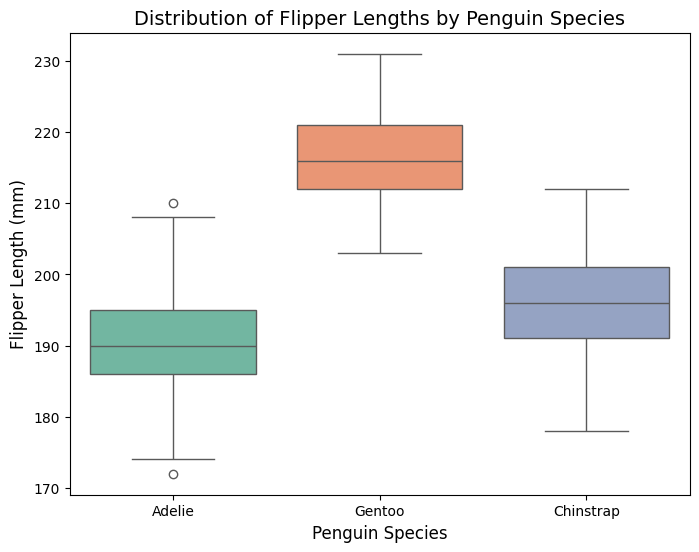

In [28]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset (replace 'penguins.csv' with your actual file path)
df = pd.read_csv('/content/drive/MyDrive/penguins.csv')

# --- 1. Summarize missing data ---
# We use .isnull() to create a boolean mask of missing values,
# then .sum() to count them per column.
print("--- Missing Data Summary ---")
missing_data = df.isnull().sum()
print(missing_data, "\n")

# --- 2. Compare flipper_length_mm across species ---
# We group the dataframe by 'species' and select the 'flipper_length_mm' column.
# The .describe() method generates summary statistics (mean, min, max, quartiles) for each species.
print("--- Flipper Length Comparison (Summary Statistics) ---")
flipper_comparison = df.groupby('species')['flipper_length_mm'].describe()
print(flipper_comparison, "\n")

# --- 3. Produce one labeled chart ---
# Set the size of the plot
plt.figure(figsize=(8, 6))

# A boxplot is ideal for comparing the distribution of a continuous variable across categories.
# It automatically shows the median, quartiles, and any outliers.
sns.boxplot(data=df, x='species', y='flipper_length_mm', palette='Set2')

# Add clear labels and a title to make the chart easy to interpret
plt.title('Distribution of Flipper Lengths by Penguin Species', fontsize=14)
plt.xlabel('Penguin Species', fontsize=12)
plt.ylabel('Flipper Length (mm)', fontsize=12)

# Display the plot
plt.show()

## Step 5: The verification checkpoint

Compute the mean flipper length per species YOURSELF with one groupby line (Tutorial 2 pattern). Compare against any per-species numbers the AI reported, and record match or mismatch in the log. If they differ, explain why (missing-value handling is the usual culprit).

In [29]:
df.groupby("species")["flipper_length_mm"].mean()

,flipper_length_mm
species,
Adelie,189.953642
Chinstrap,195.823529
Gentoo,217.186992


Both ways calculated the same mean for the species.

# Step 6: One follow-up, one judgment

Ask the AI one follow-up that improves the analysis (a better chart, an extra grouping). Run it, then keep or reject the suggestion with one sentence of your own judgment in the log.

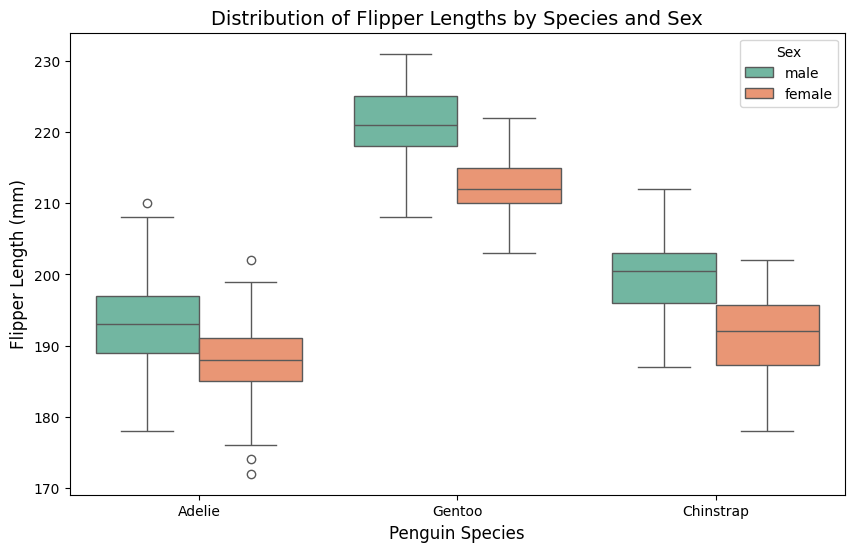

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

# Adding hue='sex' splits each species boxplot into male and female
sns.boxplot(data=df, x='species', y='flipper_length_mm', hue='sex', palette='Set2')

plt.title('Distribution of Flipper Lengths by Species and Sex', fontsize=14)
plt.xlabel('Penguin Species', fontsize=12)
plt.ylabel('Flipper Length (mm)', fontsize=12)
plt.legend(title='Sex')

plt.show()

#### Prompt log
Update the boxplot to group by both species and sex

I will keep the update because it shows how the sex of the penguin also affects the length of the flipper.

## Step 7: Your original insight, no AI

In markdown, one insight about penguins the AI did not state, backed by a number or chart you produce yourself.

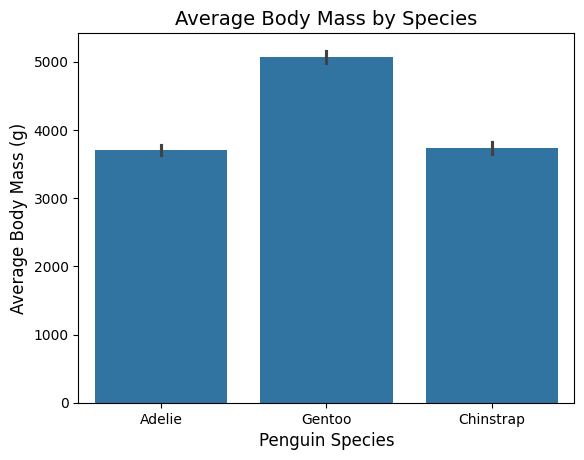

In [31]:
sns.barplot(data=df, x='species', y='body_mass_g')
plt.title('Average Body Mass by Species', fontsize=14)
plt.xlabel('Penguin Species', fontsize=12)
plt.ylabel('Average Body Mass (g)', fontsize=12)
plt.show()

When we compared the flipper length of the penguins earlier we saw chinstrap penguins had a much longer flipper than adelie penguins on average, which would have you assume that they are much larger penguins in general. However, when you compare the average body mass you see they are actually very close in mass.

## Step 8: Privacy reflection (markdown cell)

This dataset is public animals. Name one dataset from your own life or work you must NEVER paste into a public AI tool, and what you would do instead (anonymize, aggregate, or use an approved internal tool). 2–3 sentences.

I would never paste a dataset into AI that contains customer personal identification, such as names, phone number, email, and social security numbers. If i needed to use AI I would make sure to anoymize the data beforehand.